# PLB Performance Analysis Notebook

This notebook analyzes database performance metrics using the priority load balancer, including:
- **Latency Metrics** (e.g., Average Latency, 95th Percentile Latency).
- **Throughput and Goodput**.

Each plot visualizes:
- **Total Clients (Terminals)** on the outer X-axis.
- **Premium:Freemium Ratios** on the inner X-axis.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker

# Load the CSV
df = pd.read_csv("summary_results_new.csv")


In [2]:
# Combine Premium and Freemium into "Terminal Classes Weights"
df["Terminal Classes Weights"] = df.iloc[:, 5].astype(str) + "," + df.iloc[:, 6].astype(str)

# Verify the result
print("✅ Terminal Classes Weights column:")
print(df[["Terminal Classes Weights"]].head())


✅ Terminal Classes Weights column:
  Terminal Classes Weights
1                    15,35
2                    15,35
3                    40,10
4                    25,25
5                    10,40


In [3]:
# Create Clients_Label: "Total Clients (Premium:Freemium)"
def format_clients(row):
    weights = list(map(int, row["Terminal Classes Weights"].split(',')))  # Split Premium and Freemium
    total_clients = sum(weights)  # Total clients = Premium + Freemium
    return f"{total_clients} ({weights[0]}:{weights[1]})"  # Format: Total (Premium:Freemium)

# Apply the function to create the Clients_Label column
df["Clients_Label"] = df.apply(format_clients, axis=1)

# Verify the result
print("✅ Clients_Label column created!")
print(df[["Terminal Classes Weights", "Clients_Label"]].head())


✅ Clients_Label column created!
  Terminal Classes Weights Clients_Label
1                    15,35    50 (15:35)
2                    15,35    50 (15:35)
3                    40,10    50 (40:10)
4                    25,25    50 (25:25)
5                    10,40    50 (10:40)


In [4]:
# Convert latency metrics to milliseconds
latency_columns = [
    "Average Latency",
    "95th Percentile Latency",
    "Maximum Latency",
    "Median Latency",
    "Minimum Latency",
    "25th Percentile Latency",
    "90th Percentile Latency",
    "99th Percentile Latency",
    "75th Percentile Latency"
]

# Divide all latency metrics by 1,000 to convert to milliseconds
df[latency_columns] = df[latency_columns].apply(lambda x: x / 1000)

print("✅ Latency metrics converted to milliseconds!")


✅ Latency metrics converted to milliseconds!


In [5]:
# Extract the total number of clients from Clients_Label
def extract_total_clients(label):
    return int(label.split(" ")[0])  # Extract the number before the '('

df["Total Clients"] = df["Clients_Label"].apply(extract_total_clients)

# Sort by Total Clients
df = df.sort_values("Total Clients").reset_index(drop=True)

print("✅ DataFrame sorted by Total Clients!")
print(df[["Clients_Label", "Total Clients"]].head())


✅ DataFrame sorted by Total Clients!
  Clients_Label  Total Clients
0    50 (15:35)             50
1    50 (15:35)             50
2    50 (40:10)             50
3    50 (25:25)             50
4    50 (10:40)             50


In [6]:
def plot_grouped_bar_chart(df, metric, title, ylabel, output_name=None):
    """
    Function to plot grouped bar chart for a specific metric, with the same color for the same total number of terminals.
    """
    # Sort the DataFrame by Total Clients and Clients_Label
    df = df.sort_values(["Total Clients", "Clients_Label"]).reset_index(drop=True)

    # Create a color map for total clients
    unique_clients = sorted(df["Total Clients"].unique())  # Get sorted unique total clients
    color_map = {client: f"C{i}" for i, client in enumerate(unique_clients)}  # Assign a unique color for each

    fig, ax = plt.subplots(figsize=(12, 6))

    # Create positions for bars
    bar_width = 0.5
    x_positions = np.arange(len(df))  # One position per row in the DataFrame

    # Plot bars with colors based on Total Clients
    ax.bar(
        x_positions,
        df[metric],
        width=bar_width,
        color=[color_map[client] for client in df["Total Clients"]],  # Color by Total Clients
        label="Total Clients"
    )

    # Add X-axis labels for Premium:Freemium combinations
    ax.set_xticks(x_positions)
    ax.set_xticklabels(df["Clients_Label"], rotation=45, ha='right')

    # Customize the plot
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis='y')

    # Format Y-axis labels as integers
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

    # Add a legend for colors
    handles = [plt.Rectangle((0, 0), 1, 1, color=color_map[client]) for client in unique_clients]
    labels = [f"Total Clients: {client}" for client in unique_clients]
    ax.legend(handles, labels, title="Total Clients", bbox_to_anchor=(1.05, 1), loc='upper left')

    # Save the plot if output_name is provided
    if output_name:
        plt.savefig(f"{output_name}.png", dpi=300)
        plt.savefig(f"{output_name}.pdf", format="pdf")

    # Show the plot
    plt.tight_layout()
    plt.show()

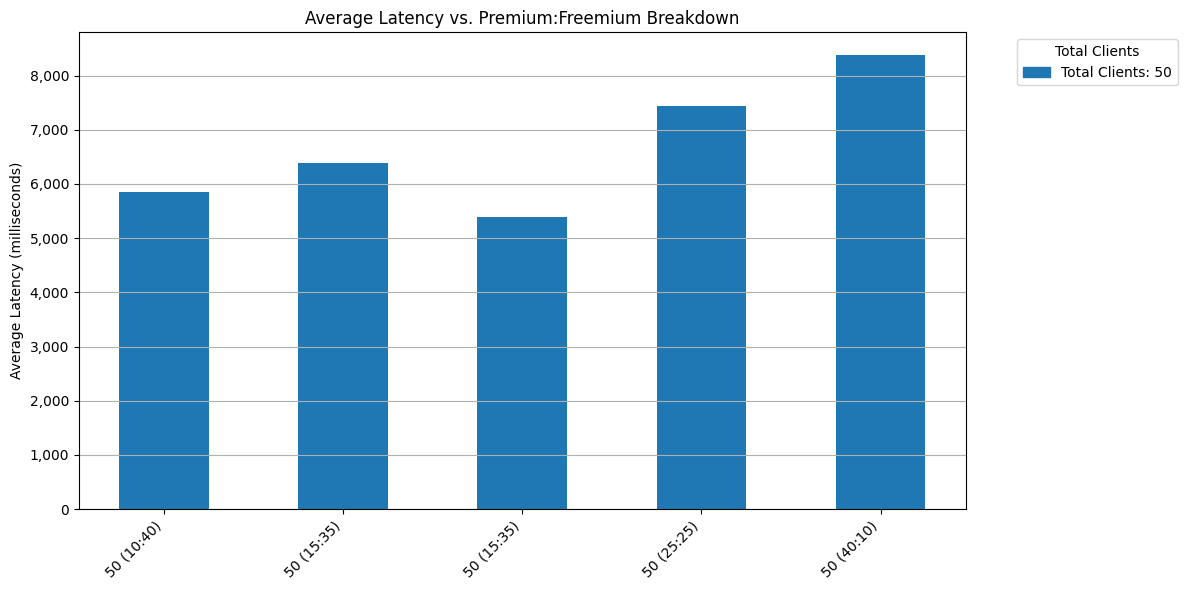

In [7]:
plot_grouped_bar_chart(
    df,
    metric="Average Latency",
    title="Average Latency vs. Premium:Freemium Breakdown",
    ylabel="Average Latency (milliseconds)",
    output_name="average_latency"
)


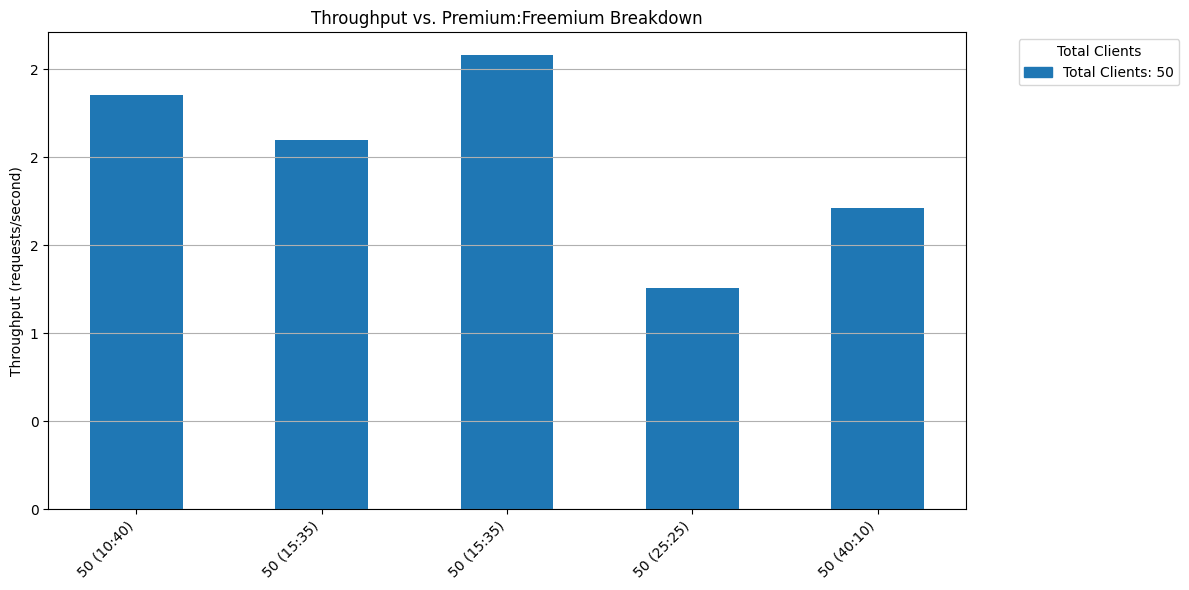

In [8]:
# Plot Throughput
plot_grouped_bar_chart(
    df,
    metric="Throughput",
    title="Throughput vs. Premium:Freemium Breakdown",
    ylabel="Throughput (requests/second)",
    output_name="throughput_sorted_final"
)

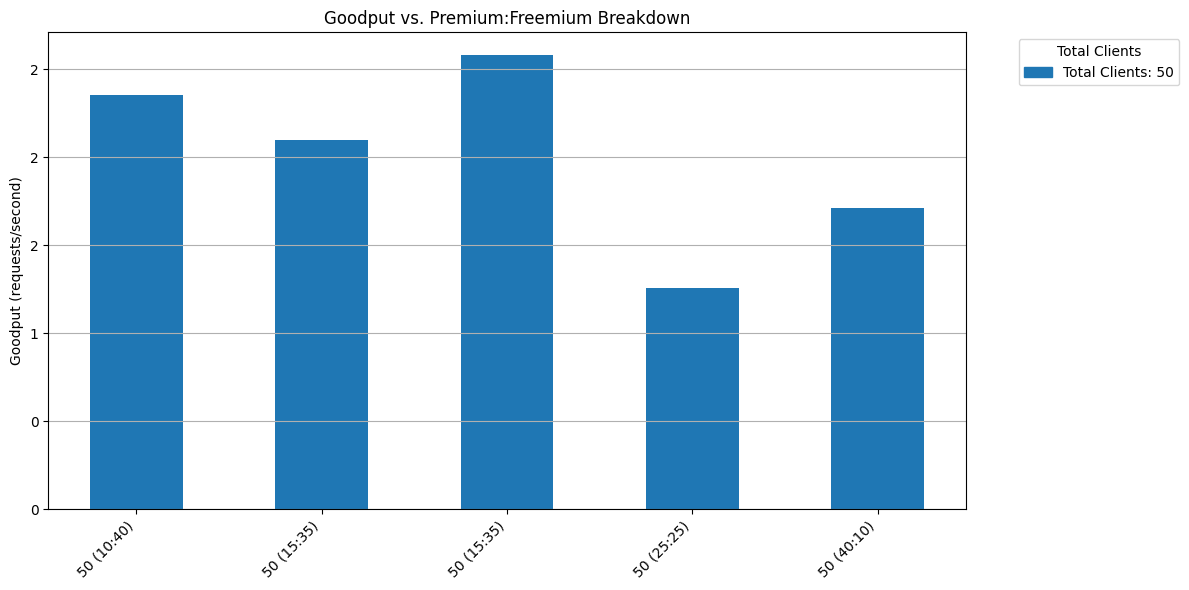

In [9]:
# Plot Goodput
plot_grouped_bar_chart(
    df,
    metric="Goodput",
    title="Goodput vs. Premium:Freemium Breakdown",
    ylabel="Goodput (requests/second)",
    output_name="goodput_sorted_final"
)
